In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

In [6]:
# Read NumPy data
infile_dir = 'graph_data'
radii = [0.25, 0.4, 1]
sources = ['co60', 'cs137']
data = np.load(infile_dir + '/radial_study_data.npz')

print("Successfully loaded data!")

Successfully loaded data!


In [7]:
N = 1000000000

def power_law_squared(x, A):
    return A / np.pow(x, 2)

radii_fit = np.arange(0.1, 1.05, 0.05)

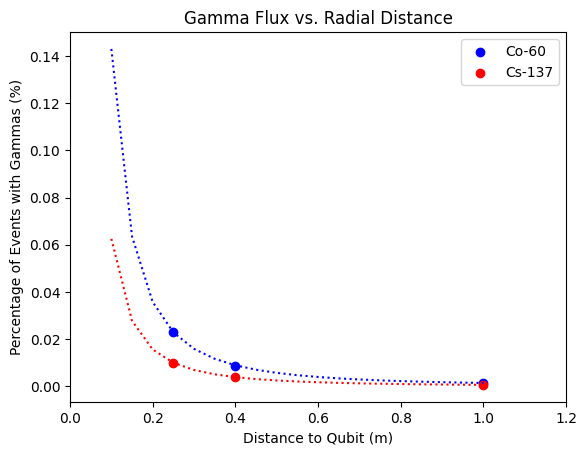

In [8]:
# Share of Events with Gammas vs. Angle
plt.scatter(radii, data['ngamma'][:len(radii)] / N * 100, color='blue', label='Co-60')
plt.errorbar(radii, data['ngamma'][:len(radii)] / N * 100, yerr=data['ngamma_std'][:len(radii)] * 100, linestyle="None", color='blue')
popt_ngamma_co60, pcov1_ngamma_co60 = curve_fit(power_law_squared, radii, data['ngamma'][:len(radii)] / N * 100, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_co60[0]), linestyle=':', color='blue')

plt.scatter(radii, data['ngamma'][len(radii):2*len(radii)] / N * 100, color='red', label='Cs-137')
plt.errorbar(radii, data['ngamma'][len(radii):2*len(radii)] / N * 100, yerr=data['ngamma_std'][len(radii):2*len(radii)] * 100, linestyle="None", color='red')
popt_ngamma_cs137, pcov1_ngamma_cs137 = curve_fit(power_law_squared, radii, data['ngamma'][len(radii):2*len(radii)] / N * 100, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_cs137[0]), linestyle=':', color='red')

# Axis labels
plt.xlim(0, 1.2)
plt.xlabel('Distance to Qubit (m)')
plt.ylabel('Percentage of Events with Gammas (%)')
plt.title('Gamma Flux vs. Radial Distance')
plt.legend()

plt.show()

In [9]:
popt_ngamma_cs137[0] / popt_ngamma_co60[0]

np.float64(0.4371910188223508)

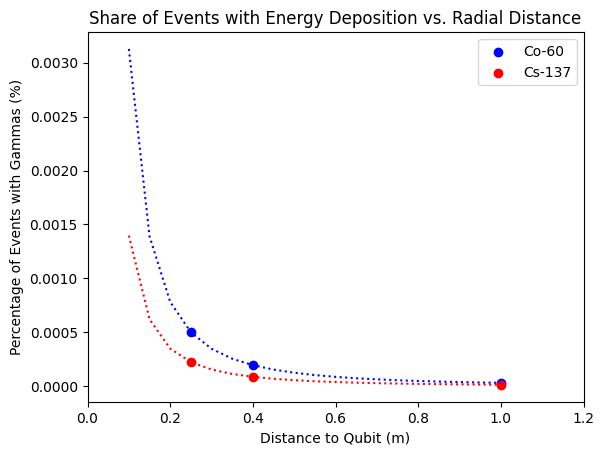

In [10]:
# Share of Events with Energy Deposition vs. Angle
plt.scatter(radii, data['energydepevts'][:len(radii)] / N * 100, color='blue', label='Co-60')
plt.errorbar(radii, data['energydepevts'][:len(radii)] / N * 100, yerr=data['energydepevts_std'][:len(radii)] * 100, linestyle="None", color='blue')
popt_energydepevts_co60, pcov1_energydepevts_co60 = curve_fit(power_law_squared, radii, data['energydepevts'][:len(radii)] / N * 100, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_energydepevts_co60[0]), linestyle=':', color='blue')

plt.scatter(radii, data['energydepevts'][len(radii):2*len(radii)] / N * 100, color='red', label='Cs-137')
plt.errorbar(radii, data['energydepevts'][len(radii):2*len(radii)] / N * 100, yerr=data['energydepevts_std'][len(radii):2*len(radii)] * 100, linestyle="None", color='red')
popt_energydepevts_cs137, pcov1_energydepevts_cs137 = curve_fit(power_law_squared, radii, data['energydepevts'][len(radii):2*len(radii)] / N * 100, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_energydepevts_cs137[0]), linestyle=':', color='red')

# Axis labels
plt.xlim(0, 1.2)
plt.xlabel('Distance to Qubit (m)')
plt.ylabel('Percentage of Events with Gammas (%)')
plt.title('Share of Events with Energy Deposition vs. Radial Distance')
plt.legend()

plt.show()

In [11]:
popt_energydepevts_cs137[0] / popt_energydepevts_co60[0]

np.float64(0.44658749702750256)

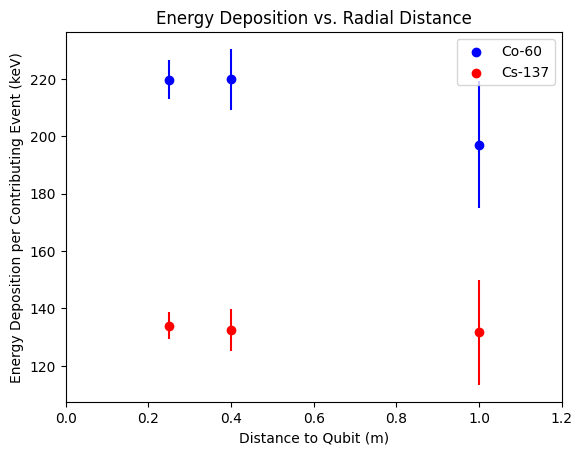

In [12]:
# Share of Events with Gammas vs. Angle
plt.scatter(radii, data['energydep'][:len(radii)] / data['energydepevts'][:len(radii)], color='blue', label='Co-60')
plt.errorbar(radii, data['energydep'][:len(radii)] / data['energydepevts'][:len(radii)], yerr=data['energydep_std'][:len(radii)], linestyle="None", color='blue')

plt.scatter(radii, data['energydep'][len(radii):2*len(radii)] / data['energydepevts'][len(radii):2*len(radii)], color='red', label='Cs-137')
plt.errorbar(radii, data['energydep'][len(radii):2*len(radii)] / data['energydepevts'][len(radii):2*len(radii)], yerr=data['energydep_std'][len(radii):2*len(radii)], linestyle="None", color='red')

# Axis labels
plt.xlim(0, 1.2)
plt.xlabel('Distance to Qubit (m)')
plt.ylabel('Energy Deposition per Contributing Event (keV)')
plt.title('Energy Deposition vs. Radial Distance')
plt.legend()

plt.show()

In [13]:
(data['energydep'][:len(radii)] / data['energydepevts'][:len(radii)]) / (data['energydep'][len(radii):2*len(radii)] / data['energydepevts'][len(radii):2*len(radii)])

array([1.63970857, 1.6594367 , 1.49677507])

In [14]:
co60_activity = 100e-6
cs137_activity = 7.26e-6
decays_per_second = 3.7e10

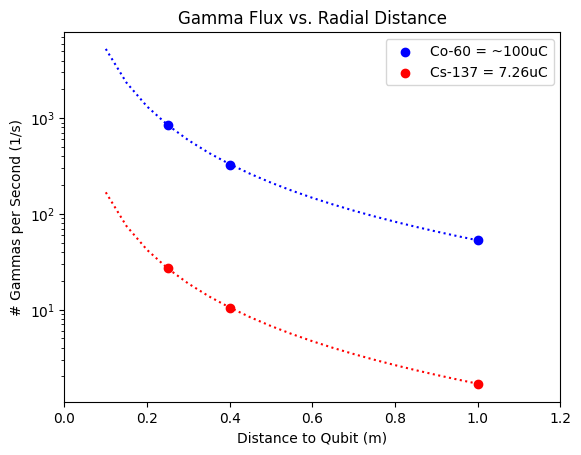

In [15]:
# Share of Events with Gammas vs. Angle
plt.scatter(radii, co60_activity * decays_per_second * data['ngamma'][:len(radii)] / N, color='blue', label='Co-60 = ~100uC')
plt.errorbar(radii, co60_activity * decays_per_second * data['ngamma'][:len(radii)] / N, yerr=co60_activity * decays_per_second * data['ngamma_std'][:len(radii)], linestyle="None", color='blue')
popt_ngamma_co60, pcov1_ngamma_co60 = curve_fit(power_law_squared, radii, co60_activity * decays_per_second * data['ngamma'][:len(radii)] / N, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_co60[0]), linestyle=':', color='blue')

plt.scatter(radii, cs137_activity * decays_per_second * data['ngamma'][len(radii):2*len(radii)] / N, color='red', label='Cs-137 = 7.26uC')
plt.errorbar(radii, cs137_activity * decays_per_second * data['ngamma'][len(radii):2*len(radii)] / N, yerr=cs137_activity * decays_per_second * data['ngamma_std'][len(radii):2*len(radii)], linestyle="None", color='red')
popt_ngamma_cs137, pcov1_ngamma_cs137 = curve_fit(power_law_squared, radii, cs137_activity * decays_per_second * data['ngamma'][len(radii):2*len(radii)] / N, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_cs137[0]), linestyle=':', color='red')

# Axis labels
plt.xlim(0, 1.2)
plt.yscale('log')
plt.xlabel('Distance to Qubit (m)')
plt.ylabel('# Gammas per Second (1/s)')
plt.title('Gamma Flux vs. Radial Distance')
plt.legend()

plt.show()

In [16]:
popt_ngamma_cs137[0] / popt_ngamma_co60[0]

np.float64(0.03174006796687321)

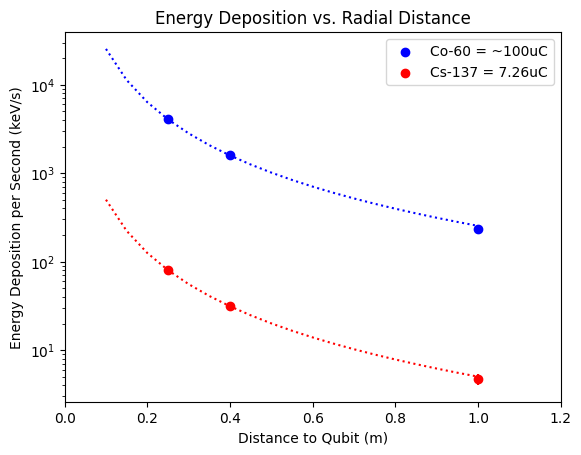

In [17]:
# Share of Events with Gammas vs. Angle
plt.scatter(radii, co60_activity * decays_per_second * data['energydep'][:len(radii)] / N, color='blue', label='Co-60 = ~100uC')
edep_co60_std = np.sqrt((data['energydepevts_std'][:len(radii)]**2) * (data['energydep_std'][:len(radii)]**2) + (data['energydep_std'][:len(radii)]**2) * ((data['energydepevts'][:len(radii)] / N)**2) + (data['energydepevts_std'][:len(radii)]**2) * (data['energydep'][:len(radii)] / data['energydepevts'][:len(radii)]**2))
plt.errorbar(radii, co60_activity * decays_per_second * data['energydep'][:len(radii)] / N, yerr=co60_activity * decays_per_second * edep_co60_std, linestyle="None", color='blue')
popt_ngamma_co60, pcov1_ngamma_co60 = curve_fit(power_law_squared, radii, co60_activity * decays_per_second * data['energydep'][:len(radii)] / N, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_co60[0]), linestyle=':', color='blue')

plt.scatter(radii, cs137_activity * decays_per_second * data['energydep'][len(radii):2*len(radii)] / N, color='red', label='Cs-137 = 7.26uC')
edep_cs137_std = np.sqrt((data['energydepevts_std'][len(radii):2*len(radii)]**2) * (data['energydep_std'][len(radii):2*len(radii)]**2) + (data['energydep_std'][len(radii):2*len(radii)]**2) * ((data['energydepevts'][len(radii):2*len(radii)] / N)**2) + (data['energydepevts_std'][len(radii):2*len(radii)]**2) * (data['energydep'][len(radii):2*len(radii)] / data['energydepevts'][len(radii):2*len(radii)]**2))
plt.errorbar(radii, cs137_activity * decays_per_second * data['energydep'][len(radii):2*len(radii)] / N, yerr=cs137_activity * decays_per_second * edep_cs137_std, linestyle="None", color='red')
popt_ngamma_cs137, pcov1_ngamma_cs137 = curve_fit(power_law_squared, radii, cs137_activity * decays_per_second * data['energydep'][len(radii):2*len(radii)] / N, p0=[1])
plt.plot(radii_fit, power_law_squared(radii_fit, popt_ngamma_cs137[0]), linestyle=':', color='red')

# Axis labels
plt.xlim(0, 1.2)
plt.yscale('log')
plt.xlabel('Distance to Qubit (m)')
plt.ylabel('Energy Deposition per Second (keV/s)')
plt.title('Energy Deposition vs. Radial Distance')
plt.legend()

plt.show()

In [18]:
popt_ngamma_cs137[0] / popt_ngamma_co60[0]

np.float64(0.019747743702151294)